---
title: "Math for Newton's Laws — Level 2"
subtitle: Vectors and first-order ODEs, written in MyST Markdown
short_title: Math for Newton (L2)
numbering:
  heading_2: true
  equation: true
---

# Vectors and ODEs for Newton's Laws

:::{tip} Where this sits in the plan
This is step 1 of the *math before physics* sequence: **vectors and first-order ODEs**, to be done before Taylor 1–4.

| Book | Approximate chapters |
|---|---|
| Stewart | 9 (first-order ODEs), 12 (vectors) |
| Boas | 6 (vector analysis), 8 (ODEs) |
| Zill | 2 (first-order ODEs) |
| Arfken | 3 (vectors, curvilinear coordinates), 7 (ODEs) |

Chapter numbers are approximate, as in the workbook. The div/curl/Stokes material belongs to step 7 (before E&M) and is covered in the separate vector calculus notes.
:::

Each section ends with what the Newton's laws notes use it for. Exercises have a **hint** dropdown and a separate **answer** dropdown. The code cells are written to be read, so most are left visible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (7, 4.6),
    "axes.grid": True,
    "grid.alpha": 0.3,
})

## Vector Algebra and Index Notation

A vector in three dimensions is a list of three components relative to an orthonormal basis $\mathbf{e}_1, \mathbf{e}_2, \mathbf{e}_3$ (also written $\hat{\mathbf{x}}, \hat{\mathbf{y}}, \hat{\mathbf{z}}$):

$$
\mathbf{A} = A_1\mathbf{e}_1 + A_2\mathbf{e}_2 + A_3\mathbf{e}_3 = \sum_i A_i\mathbf{e}_i .
$$

### The dot product

$$
\mathbf{A}\cdot\mathbf{B} = \sum_i A_iB_i = |\mathbf{A}||\mathbf{B}|\cos\theta .
$$ (eq-dot)

Two readings are useful:

- **Angle.** $\cos\theta = \mathbf{A}\cdot\mathbf{B}/(|\mathbf{A}||\mathbf{B}|)$. A zero dot product means perpendicular.
- **Projection.** $\mathbf{A}\cdot\hat{\mathbf{n}}$ is the component of $\mathbf{A}$ along the unit vector $\hat{\mathbf{n}}$. Every "component of the force along the incline" in mechanics is a dot product.

### The cross product

$$
\mathbf{A}\times\mathbf{B} =
\begin{vmatrix}\mathbf{e}_1 & \mathbf{e}_2 & \mathbf{e}_3 \\ A_1 & A_2 & A_3 \\ B_1 & B_2 & B_3\end{vmatrix}
= \langle A_2B_3 - A_3B_2,\; A_3B_1 - A_1B_3,\; A_1B_2 - A_2B_1\rangle .
$$ (eq-cross)

Its direction is perpendicular to both factors, set by the right-hand rule, and its magnitude $|\mathbf{A}||\mathbf{B}|\sin\theta$ is the area of the parallelogram they span. It is **antisymmetric**: $\mathbf{B}\times\mathbf{A} = -\mathbf{A}\times\mathbf{B}$, so $\mathbf{A}\times\mathbf{A} = \mathbf{0}$.

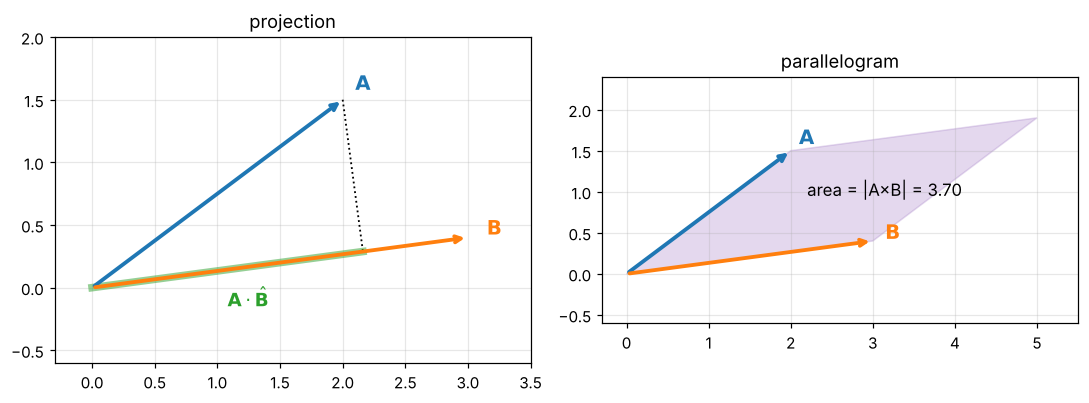

In [2]:
#| label: fig-dot-cross
#| caption: Left, the dot product as a projection, the shadow of A on the direction of B. Right, the magnitude of the cross product as the area of the parallelogram spanned by A and B.
A = np.array([2.0, 1.5]); B = np.array([3.0, 0.4])
Bhat = B / np.linalg.norm(B)
proj = (A @ Bhat) * Bhat

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
for v, c, lab in [(A, "tab:blue", r"$\mathbf{A}$"), (B, "tab:orange", r"$\mathbf{B}$")]:
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
    ax.text(*(v * 1.05), lab, color=c, fontsize=13)
ax.plot([A[0], proj[0]], [A[1], proj[1]], "k:", lw=1.2)
ax.plot([0, proj[0]], [0, proj[1]], color="tab:green", lw=5, alpha=0.5)
ax.text(proj[0] / 2, proj[1] / 2 - 0.3, r"$\mathbf{A}\cdot\hat{\mathbf{B}}$", color="tab:green", fontsize=12)
ax.set_xlim(-0.3, 3.5); ax.set_ylim(-0.6, 2); ax.set_aspect("equal"); ax.set_title("projection")

ax = axes[1]
ax.fill([0, A[0], A[0] + B[0], B[0]], [0, A[1], A[1] + B[1], B[1]], color="tab:purple", alpha=0.25)
for v, c, lab in [(A, "tab:blue", r"$\mathbf{A}$"), (B, "tab:orange", r"$\mathbf{B}$")]:
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
    ax.text(*(v * 1.05), lab, color=c, fontsize=13)
area = abs(A[0] * B[1] - A[1] * B[0])
ax.text(2.2, 0.95, f"area = |A×B| = {area:.2f}", fontsize=11)
ax.set_xlim(-0.3, 5.5); ax.set_ylim(-0.6, 2.4); ax.set_aspect("equal"); ax.set_title("parallelogram")
plt.tight_layout(); plt.show()

### Index notation

Two symbols make most vector identities mechanical.

:::{prf:definition} Kronecker delta and Levi-Civita symbol
:label: def-delta-epsilon

$$
\delta_{ij} = \begin{cases} 1 & i = j \\ 0 & i\neq j\end{cases},
\qquad
\varepsilon_{ijk} = \begin{cases} +1 & (ijk) \text{ an even permutation of } (123) \\ -1 & \text{an odd permutation} \\ 0 & \text{any index repeated.}\end{cases}
$$

With them, $\mathbf{e}_i\cdot\mathbf{e}_j = \delta_{ij}$, $\ \mathbf{A}\cdot\mathbf{B} = \sum_i A_iB_i$, and

$$
(\mathbf{A}\times\mathbf{B})_i = \sum_{j,k}\varepsilon_{ijk}A_jB_k .
$$
:::

The one identity worth memorizing connects the two symbols:

$$
\sum_k \varepsilon_{ijk}\,\varepsilon_{lmk} = \delta_{il}\delta_{jm} - \delta_{im}\delta_{jl} .
$$ (eq-eps-delta)

::::{prf:example} The BAC–CAB rule
:label: ex-bac-cab

Show that $\mathbf{A}\times(\mathbf{B}\times\mathbf{C}) = \mathbf{B}(\mathbf{A}\cdot\mathbf{C}) - \mathbf{C}(\mathbf{A}\cdot\mathbf{B})$.

:::{dropdown} Solution
Write the $i$-th component, cycle the indices on the first $\varepsilon$ so the summed index is last ($\varepsilon_{ijk} = \varepsilon_{jki}$), and apply {eq}`eq-eps-delta`:

$$
\begin{aligned}
\big[\mathbf{A}\times(\mathbf{B}\times\mathbf{C})\big]_i
&= \sum_{j,k}\varepsilon_{ijk}A_j\sum_{l,m}\varepsilon_{klm}B_lC_m
 = \sum_{j,l,m}\Big(\sum_k\varepsilon_{ijk}\varepsilon_{lmk}\Big)A_jB_lC_m \\
&= \sum_{j,l,m}\big(\delta_{il}\delta_{jm} - \delta_{im}\delta_{jl}\big)A_jB_lC_m
 = B_i\,(\mathbf{A}\cdot\mathbf{C}) - C_i\,(\mathbf{A}\cdot\mathbf{B}) .
\end{aligned}
$$

(Here $\varepsilon_{klm} = \varepsilon_{lmk}$, another cyclic shift.) The deltas just rename indices, which is why the last step is immediate.
:::
::::

In [3]:
# Brute-force check of the epsilon-delta identity over all 81 index combinations
from sympy import LeviCivita, KroneckerDelta

ok = all(
    sum(LeviCivita(i, j, k) * LeviCivita(l, m, k) for k in range(3))
    == KroneckerDelta(i, l) * KroneckerDelta(j, m) - KroneckerDelta(i, m) * KroneckerDelta(j, l)
    for i in range(3) for j in range(3) for l in range(3) for m in range(3)
)
print("epsilon-delta identity holds:", ok)

# BAC-CAB with symbolic vectors
A = sp.Matrix(sp.symbols("A1:4")); B = sp.Matrix(sp.symbols("B1:4")); C = sp.Matrix(sp.symbols("C1:4"))
lhs = A.cross(B.cross(C))
rhs = B * A.dot(C) - C * A.dot(B)
print("BAC-CAB holds:", sp.simplify(lhs - rhs) == sp.zeros(3, 1))

epsilon-delta identity holds: True
BAC-CAB holds: True


:::{note} Used in the Newton's laws notes for
Components of forces along inclines (dot products), torque and angular momentum (cross products), the magnetic force $q\mathbf{v}\times\mathbf{B}$, and the index-notation style Goldstein uses throughout.
:::

### Exercises

1. For $\mathbf{A} = \langle1,2,2\rangle$ and $\mathbf{B} = \langle2,-1,0\rangle$, find the angle between them and $\mathbf{A}\times\mathbf{B}$. Check that $|\mathbf{A}\times\mathbf{B}| = |\mathbf{A}||\mathbf{B}|\sin\theta$.
2. Use index notation to show that $(\mathbf{A}\times\mathbf{B})\cdot\mathbf{A} = 0$.

:::{dropdown} Hints
1. Compute the dot product first. It makes the sine easy.
2. Write the expression as $\sum_{ijk}\varepsilon_{ijk}A_jB_kA_i$. What happens when you swap the names $i$ and $j$?
:::

:::{dropdown} Answers
1. $\mathbf{A}\cdot\mathbf{B} = 0$, so $\theta = 90^\circ$. $\mathbf{A}\times\mathbf{B} = \langle 2, 4, -5\rangle$, with magnitude $\sqrt{45} = 3\sqrt5 = |\mathbf{A}||\mathbf{B}|$.
2. $\varepsilon_{ijk}$ changes sign when $i$ and $j$ swap, but $A_iA_j$ does not. A sum of an antisymmetric factor times a symmetric one is zero.
:::

## Differentiating Vectors

If $\mathbf{A}(t)$ has components $A_i(t)$ in a **fixed** basis, then $\dot{\mathbf{A}} = \sum_i \dot A_i\mathbf{e}_i$. The product rules work as in ordinary calculus:

$$
\frac{d}{dt}(f\mathbf{A}) = \dot f\mathbf{A} + f\dot{\mathbf{A}},\qquad
\frac{d}{dt}(\mathbf{A}\cdot\mathbf{B}) = \dot{\mathbf{A}}\cdot\mathbf{B} + \mathbf{A}\cdot\dot{\mathbf{B}},\qquad
\frac{d}{dt}(\mathbf{A}\times\mathbf{B}) = \dot{\mathbf{A}}\times\mathbf{B} + \mathbf{A}\times\dot{\mathbf{B}} .
$$

Keep the order in the last one, since the cross product is not commutative.

:::{prf:theorem} Constant length means perpendicular derivative
:label: thm-const-length

If $|\mathbf{A}(t)|$ is constant, then $\dot{\mathbf{A}}\perp\mathbf{A}$.
:::

:::{prf:proof}
:class: dropdown
$\mathbf{A}\cdot\mathbf{A}$ is constant, so $0 = \frac{d}{dt}(\mathbf{A}\cdot\mathbf{A}) = 2\mathbf{A}\cdot\dot{\mathbf{A}}$.
:::

Two consequences come up constantly:

- A **unit vector** can only change direction, so its derivative is perpendicular to it. This is why $d\hat{\mathbf{r}}/dt$ points along $\hat{\boldsymbol\phi}$ in polar coordinates.
- A vector of fixed length **rotating** with angular velocity $\boldsymbol\omega$ satisfies

$$
\dot{\mathbf{A}} = \boldsymbol\omega\times\mathbf{A} .
$$ (eq-rotating-vector)

  This formula is the starting point for rotating reference frames (the Coriolis and centrifugal forces) and rigid-body motion.

:::{note} Used in the Newton's laws notes for
The derivatives of the polar unit vectors, the statement that a magnetic force (always perpendicular to $\mathbf{v}$) cannot change the speed, and the product-rule step in proving $\mathbf{F} = \dot{\mathbf{p}}$ for a system.
:::

### Exercises

1. Let $\mathbf{A}(t) = \langle R\cos\omega t,\ R\sin\omega t,\ h\rangle$. Verify {eq}`eq-rotating-vector` with $\boldsymbol\omega = \omega\hat{\mathbf{z}}$.
2. Show that $\dfrac{d}{dt}(\mathbf{r}\times\mathbf{v}) = \mathbf{r}\times\mathbf{a}$.

:::{dropdown} Hints
1. Compute $\omega\hat{\mathbf{z}}\times\mathbf{A}$ with {eq}`eq-cross` and compare with the derivative.
2. Use the cross-product rule. One of the two terms is a vector crossed with itself.
:::

:::{dropdown} Answers
1. Both sides equal $\langle -R\omega\sin\omega t,\ R\omega\cos\omega t,\ 0\rangle$.
2. $\frac{d}{dt}(\mathbf{r}\times\mathbf{v}) = \mathbf{v}\times\mathbf{v} + \mathbf{r}\times\mathbf{a} = \mathbf{r}\times\mathbf{a}$. Multiplied by $m$, this says the rate of change of angular momentum equals the torque.
:::

## Curvilinear Coordinates

Cartesian unit vectors are the same everywhere. In curvilinear coordinates the unit vectors depend on position, and that is the only source of the extra terms in polar-coordinate velocities and accelerations.

### Cylindrical coordinates $(\rho, \phi, z)$

Plane polar coordinates plus a height:

$$
\hat{\boldsymbol\rho} = \langle\cos\phi, \sin\phi, 0\rangle,\qquad
\hat{\boldsymbol\phi} = \langle-\sin\phi, \cos\phi, 0\rangle,\qquad
\hat{\mathbf{z}} .
$$

Only $\phi$ moves the basis: $\dot{\hat{\boldsymbol\rho}} = \dot\phi\,\hat{\boldsymbol\phi}$ and $\dot{\hat{\boldsymbol\phi}} = -\dot\phi\,\hat{\boldsymbol\rho}$. Starting from $\mathbf{r} = \rho\hat{\boldsymbol\rho} + z\hat{\mathbf{z}}$,

$$
\begin{aligned}
\mathbf{v} &= \dot\rho\,\hat{\boldsymbol\rho} + \rho\dot\phi\,\hat{\boldsymbol\phi} + \dot z\,\hat{\mathbf{z}}, \\
\mathbf{a} &= \big(\ddot\rho - \rho\dot\phi^2\big)\hat{\boldsymbol\rho} + \big(\rho\ddot\phi + 2\dot\rho\dot\phi\big)\hat{\boldsymbol\phi} + \ddot z\,\hat{\mathbf{z}} .
\end{aligned}
$$

### Spherical coordinates $(r, \theta, \phi)$

Using the physics convention ($\theta$ from the $+z$ axis, $\phi$ around it):

$$
\hat{\mathbf{r}} = \langle\sin\theta\cos\phi,\ \sin\theta\sin\phi,\ \cos\theta\rangle,\quad
\hat{\boldsymbol\theta} = \langle\cos\theta\cos\phi,\ \cos\theta\sin\phi,\ -\sin\theta\rangle,\quad
\hat{\boldsymbol\phi} = \langle-\sin\phi,\ \cos\phi,\ 0\rangle .
$$

The velocity is

$$
\mathbf{v} = \dot r\,\hat{\mathbf{r}} + r\dot\theta\,\hat{\boldsymbol\theta} + r\sin\theta\,\dot\phi\,\hat{\boldsymbol\phi} .
$$ (eq-spherical-v)

The coefficients $1$, $r$, $r\sin\theta$ are the **scale factors**: a small change $d\theta$ moves the point a distance $r\,d\theta$, and a small change $d\phi$ moves it $r\sin\theta\,d\phi$ (the radius of the circle of latitude). The same scale factors appear in the volume element $r^2\sin\theta\,dr\,d\theta\,d\phi$ and in the gradient.

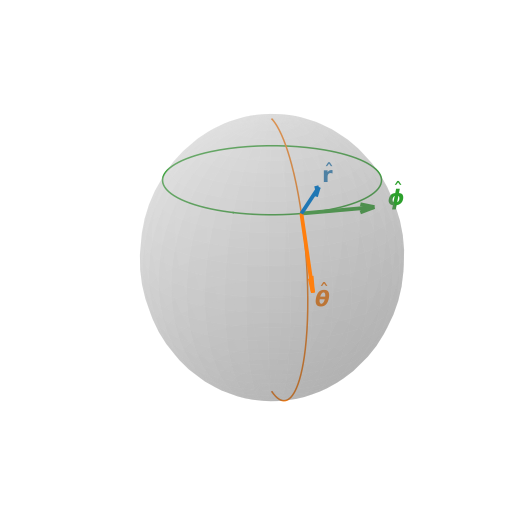

In [4]:
#| label: fig-spherical-basis
#| caption: The spherical unit vectors at a point on a sphere. r̂ points outward, θ̂ points south along a meridian, φ̂ points east along a circle of latitude.
fig = plt.figure(figsize=(6.4, 6))
ax = fig.add_subplot(projection="3d")
u, v = np.meshgrid(np.linspace(0, np.pi, 30), np.linspace(0, 2 * np.pi, 40))
ax.plot_surface(np.sin(u) * np.cos(v), np.sin(u) * np.sin(v), np.cos(u), color="lightgray", alpha=0.25, linewidth=0)

th, ph = np.radians(55), np.radians(35)
p = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
basis = {
    r"$\hat{\mathbf{r}}$": (p, "tab:blue"),
    r"$\hat{\boldsymbol{\theta}}$": (np.array([np.cos(th) * np.cos(ph), np.cos(th) * np.sin(ph), -np.sin(th)]), "tab:orange"),
    r"$\hat{\boldsymbol{\phi}}$": (np.array([-np.sin(ph), np.cos(ph), 0.0]), "tab:green"),
}
for lab, (e, c) in basis.items():
    ax.quiver(*p, *(0.55 * e), color=c, lw=2.5, arrow_length_ratio=0.2)
    ax.text(*(p + 0.65 * e), lab, color=c, fontsize=14)

t = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.sin(th) * np.cos(t), np.sin(th) * np.sin(t), np.cos(th) + 0 * t, color="tab:green", lw=1)
s = np.linspace(0, np.pi, 200)
ax.plot(np.sin(s) * np.cos(ph), np.sin(s) * np.sin(ph), np.cos(s), color="tab:orange", lw=1)
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
ax.view_init(elev=20, azim=20)
plt.show()

In [5]:
# Let sympy confirm the spherical velocity: project d(r r_hat)/dt onto each unit vector
t = sp.symbols("t")
r, th, ph = [sp.Function(n)(t) for n in ("r", "theta", "phi")]
rhat = sp.Matrix([sp.sin(th) * sp.cos(ph), sp.sin(th) * sp.sin(ph), sp.cos(th)])
thhat = sp.Matrix([sp.cos(th) * sp.cos(ph), sp.cos(th) * sp.sin(ph), -sp.sin(th)])
phhat = sp.Matrix([-sp.sin(ph), sp.cos(ph), 0])
v = (r * rhat).diff(t)
for name, e in [("v_r", rhat), ("v_theta", thhat), ("v_phi", phhat)]:
    print(f"{name:8s}=", sp.simplify(v.dot(e)))

v_r     = Derivative(r(t), t)
v_theta = r(t)*Derivative(theta(t), t)
v_phi   = r(t)*sin(theta(t))*Derivative(phi(t), t)


:::{note} Used in the Newton's laws notes for
The polar-coordinate form of $\mathbf{F} = m\mathbf{a}$, the pendulum, and the string pulled through a hole. Spherical coordinates take over in central-force problems and in E&M.
:::

### Exercises

1. A particle moves on the helix $\rho = R$, $\phi = \omega t$, $z = ut$. Find its velocity and acceleration in cylindrical components.
2. A particle moves on a sphere of radius $R$ along a circle of fixed latitude ($\theta$ constant) with $\dot\phi = \Omega$. Use {eq}`eq-spherical-v` to find its speed.

:::{dropdown} Hints
1. Most of the derivatives vanish. Keep track of which ones survive.
2. Only one term of {eq}`eq-spherical-v` survives.
:::

:::{dropdown} Answers
1. $\mathbf{v} = R\omega\,\hat{\boldsymbol\phi} + u\,\hat{\mathbf{z}}$ and $\mathbf{a} = -R\omega^2\,\hat{\boldsymbol\rho}$. The acceleration is purely centripetal, as in the magnetic helix.
2. $v = R\sin\theta\,\Omega$. It is largest on the equator and zero at the poles.
:::

## The Gradient and Potential Energy

At Level 2 the gradient appears mostly as the link between a potential energy $U$ and its force. For a function $U(x,y,z)$,

$$
\nabla U = \left\langle \frac{\partial U}{\partial x},\ \frac{\partial U}{\partial y},\ \frac{\partial U}{\partial z}\right\rangle,
\qquad dU = \nabla U\cdot d\mathbf{r} .
$$

The second equation is the useful one. It says the change in $U$ over a small step is the component of the step along $\nabla U$, so $\nabla U$ points in the direction of steepest increase. A conservative force is

$$
\mathbf{F} = -\nabla U ,
$$

pointing downhill in energy. In spherical coordinates, for a function of $r$ only, $\nabla U = U'(r)\,\hat{\mathbf{r}}$.

:::{tip} Connection to the vector calculus notes
The full story (line integrals, the curl test for conservative fields, path independence) is in the Chapter 16 notes, sections 16.1–16.3 and 16.5. You only need the definition and $\mathbf{F} = -\nabla U$ for the Newton's laws material. The rest is needed for the energy row of the ladder.
:::

### Exercises

1. Find the force for $U = \tfrac12k(x^2 + y^2)$.
2. Find the force for $U = -GMm/r$.

:::{dropdown} Hints
1. Take the partial derivatives one at a time.
2. Use $\nabla U = U'(r)\,\hat{\mathbf{r}}$.
:::

:::{dropdown} Answers
1. $\mathbf{F} = -k\langle x, y\rangle$, a two-dimensional spring pulling toward the origin.
2. $\mathbf{F} = -\dfrac{GMm}{r^2}\hat{\mathbf{r}}$, Newtonian gravity.
:::

## What an ODE Is

An **ordinary differential equation** relates an unknown function of one variable to its derivatives. Newton's second law $m\ddot x = F(x, \dot x, t)$ is the central example in mechanics.

:::{prf:definition} Classifying ODEs
:label: def-ode-classes

- The **order** is the highest derivative that appears.
- An ODE is **linear** if the unknown and its derivatives appear only to the first power and are not multiplied together: $a_n(t)y^{(n)} + \cdots + a_1(t)\dot y + a_0(t)y = q(t)$.
- A linear ODE is **homogeneous** if $q(t) = 0$.
- An ODE is **autonomous** if the independent variable $t$ does not appear explicitly.
:::

Linearity is the property that matters most. Solutions of a linear homogeneous equation can be added and scaled (the **superposition principle**), and that is what makes oscillations, waves and quantum mechanics tractable. Nonlinear equations (the full pendulum, quadratic drag in 2D) usually need numerical methods or clever tricks.

### Initial value problems and uniqueness

A first-order equation $\dot y = f(t,y)$ with a starting value $y(t_0) = y_0$ is an **initial value problem**. If $f$ and $\partial f/\partial y$ are continuous near $(t_0, y_0)$, there is exactly one solution near $t_0$. For Newton's second law that means: given position and velocity now, the future is determined.

The continuity condition is not a technicality. When $\partial f/\partial y$ blows up, uniqueness can fail.

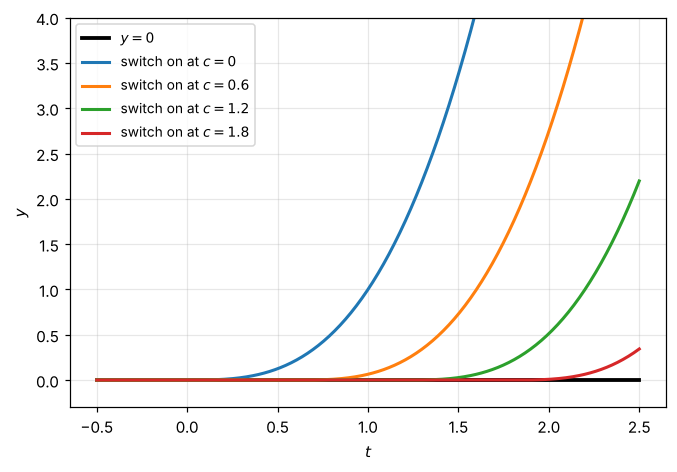

In [6]:
#| label: fig-nonunique
#| caption: The equation y' = 3y^(2/3) with y(0) = 0 has infinitely many solutions. The function y = 0 works, and so does y = (t − c)³ switched on at any time c ≥ 0. The uniqueness theorem fails because ∂f/∂y = 2y^(-1/3) blows up at y = 0.
t = np.linspace(-0.5, 2.5, 400)
fig, ax = plt.subplots()
ax.plot(t, 0 * t, "k", lw=2.5, label="$y = 0$")
for c, col in [(0, "tab:blue"), (0.6, "tab:orange"), (1.2, "tab:green"), (1.8, "tab:red")]:
    y = np.where(t > c, (t - c)**3, 0.0)
    ax.plot(t, y, color=col, lw=2, label=f"switch on at $c = {c}$")
ax.set_ylim(-0.3, 4); ax.set_xlabel("$t$"); ax.set_ylabel("$y$")
ax.legend(fontsize=9); plt.show()

### Slope fields

A first-order equation $\dot y = f(t,y)$ assigns a slope to every point of the $(t,y)$ plane. Drawing short segments with those slopes gives a **slope field**, and every solution curve runs tangent to it. A slope field shows qualitative behavior (equilibria, growth, decay) before you solve anything.

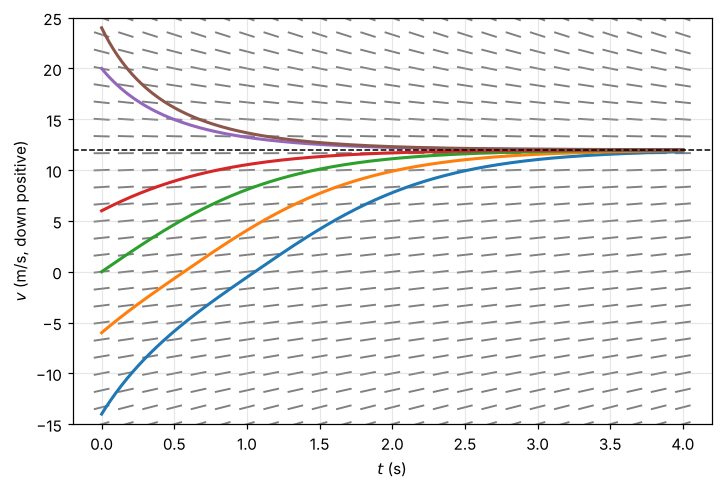

In [7]:
#| label: fig-slope-field
#| caption: Slope field for falling with quadratic drag, dv/dt = g − k v|v| (down positive). Every solution approaches terminal velocity (dashed), whether it starts below it, above it, or moving upward.
gval, vt = 9.81, 12.0
k = gval / vt**2
f = lambda t, v: gval - k * v * np.abs(v)

T, V = np.meshgrid(np.linspace(0, 4, 25), np.linspace(-15, 25, 25))
S = f(T, V)
L = np.hypot(1, S / 6)                      # normalize segments in plot units
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.quiver(T, V, 1 / L, (S / 6) / L, angles="xy", color="gray", headwidth=0, headlength=0,
          headaxislength=0, pivot="middle", scale=40, width=0.003)
for v0 in [-14, -6, 0, 6, 20, 24]:
    sol = solve_ivp(f, (0, 4), [v0], dense_output=True, max_step=0.01)
    tt = np.linspace(0, 4, 300)
    ax.plot(tt, sol.sol(tt)[0], lw=2)
ax.axhline(vt, color="k", ls="--", lw=1)
ax.set_xlabel("$t$ (s)"); ax.set_ylabel("$v$ (m/s, down positive)")
ax.set_ylim(-15, 25); plt.show()

### Exercises

Classify each equation by order, linearity, homogeneity and whether it is autonomous.

1. $\ddot\theta + \sin\theta = 0$
2. $\dot v = g - v/\tau$
3. $t^2\ddot y + t\dot y + y = 0$

:::{dropdown} Hint
For linearity, look only at how the unknown function appears. Coefficients may depend on $t$.
:::

:::{dropdown} Answers
1. Second order, nonlinear ($\sin\theta$), autonomous. Homogeneity applies only to linear equations.
2. First order, linear, inhomogeneous (the constant $g$), autonomous.
3. Second order, linear, homogeneous, not autonomous (variable coefficients). This is an Euler (equidimensional) equation.
:::

## Separable Equations

A first-order equation is **separable** if it factors as $\dot y = g(t)\,h(y)$. Move everything with $y$ to one side and integrate:

$$
\int\frac{dy}{h(y)} = \int g(t)\,dt + C .
$$ (eq-separable)

In mechanics the most common case is an autonomous equation $\dot v = f(v)$, a force that depends only on velocity. Then

$$
t = \int_{v_0}^{v}\frac{dv'}{f(v')} ,
$$

which gives $t$ as a function of $v$. Invert it to get $v(t)$ when you can.

:::{warning} Do not lose the constant solutions
Dividing by $h(y)$ assumes $h(y)\neq 0$. Any value $y^*$ with $h(y^*) = 0$ is a **constant solution** (an equilibrium) that the formula misses. For falling with drag, that missed solution is the terminal velocity itself.
:::

::::{prf:example} Falling with quadratic drag
:label: ex-sep-quad

Solve $\dot v = g\left(1 - v^2/v_t^2\right)$ with $v(0) = 0$.

:::{dropdown} Solution
Separate:

$$
\int_0^{v}\frac{dv'}{1 - v'^2/v_t^2} = gt .
$$

With $u = v'/v_t$, the integral is $v_t\tanh^{-1}(v/v_t)$ (or use partial fractions: $\frac{1}{1-u^2} = \frac12\left[\frac{1}{1-u} + \frac{1}{1+u}\right]$, giving $\frac{v_t}{2}\ln\frac{1+u}{1-u}$, the same thing). So

$$
v(t) = v_t\tanh\!\left(\frac{gt}{v_t}\right) .
$$

The constant solution $v = v_t$ is the equilibrium the separation divided out. The tanh solution approaches it but never reaches it.
:::
::::

In [8]:
# sympy recognizes separable equations; here are the two drag cases
t = sp.symbols("t", nonnegative=True)
g, vt, k, v0 = sp.symbols("g v_t k v_0", positive=True)
v = sp.Function("v")

ode = sp.Eq(v(t).diff(t), g * (1 - v(t)**2 / vt**2))
print("quadratic drag, general   :", sp.dsolve(ode, v(t)).rhs)
# dsolve's general form is awkward to pin down here, so check the tanh answer directly instead
candidate = sp.Eq(v(t), vt * sp.tanh(g * t / vt))
print("tanh solution satisfies it:", sp.checkodesol(ode, candidate)[0], "| v(0) =", candidate.rhs.subs(t, 0))

coast = sp.dsolve(sp.Eq(v(t).diff(t), -k * v(t)**2), v(t), ics={v(0): v0})
print("coasting, v' = -k v^2     :", sp.simplify(coast.rhs))

quadratic drag, general   : v_t/tanh((C1*v_t**2 + g*t)/v_t)
tanh solution satisfies it: True | v(0) = 0
coasting, v' = -k v^2     : v_0/(k*t*v_0 + 1)


### Exercises

1. Solve $\dot v = -kv^{3/2}$ with $v(0) = v_0$.
2. Solve the logistic equation $\dot y = y(1 - y)$ with $y(0) = y_0$, using partial fractions.

:::{dropdown} Hints
1. $\int v^{-3/2}\,dv = -2v^{-1/2}$.
2. $\dfrac{1}{y(1-y)} = \dfrac1y + \dfrac{1}{1-y}$.
:::

:::{dropdown} Answers
1. $v(t) = \left(v_0^{-1/2} + \tfrac12 kt\right)^{-2}$.
2. $\ln\left|\dfrac{y}{1-y}\right| = t + C$, so $y(t) = \dfrac{1}{1 + Ae^{-t}}$ with $A = (1 - y_0)/y_0$. The constant solutions $y = 0$ and $y = 1$ were divided out.
:::

## Linear First-Order Equations

A linear first-order equation has the standard form

$$
\dot y + p(t)\,y = q(t) .
$$ (eq-linear-first)

### The integrating factor

Multiply by $\mu(t) = e^{\int p\,dt}$. Because $\dot\mu = p\mu$, the left side becomes an exact derivative:

$$
\mu\dot y + \mu p\,y = \frac{d}{dt}(\mu y) = \mu q .
$$

Integrate and divide by $\mu$:

$$
y(t) = \frac{1}{\mu(t)}\left[\int \mu(t)\,q(t)\,dt + C\right] .
$$ (eq-int-factor)

### Structure of the solution

The result always has the form

$$
y = \underbrace{y_p(t)}_{\text{particular}} + \underbrace{C\,e^{-\int p\,dt}}_{\text{homogeneous}} .
$$

The homogeneous part carries the initial condition. When $p > 0$ it decays, so it is the **transient**. The particular part is what remains, the **steady state**. This split between transient and steady-state response is the same one you will use for driven oscillators and AC circuits.

::::{prf:example} Linear drag with a periodic push
:label: ex-driven-linear

A puck with linear drag is pushed back and forth: $\dot v + v/\tau = A\cos\omega t$. Find the long-time behavior.

:::{dropdown} Solution
Here $p = 1/\tau$ and $\mu = e^{t/\tau}$. The integral $\int e^{t/\tau}\cos\omega t\,dt$ is easiest with complex exponentials (see the complex-number section). Write $\cos\omega t = \operatorname{Re}\,e^{i\omega t}$ and try $v_p = \operatorname{Re}\,\big(Ve^{i\omega t}\big)$:

$$
\left(i\omega + \frac1\tau\right)V = A \quad\Longrightarrow\quad V = \frac{A\tau}{1 + i\omega\tau} .
$$

Taking the real part,

$$
v_p(t) = \frac{A\tau}{1 + \omega^2\tau^2}\Big(\cos\omega t + \omega\tau\sin\omega t\Big) .
$$

The full solution adds $Ce^{-t/\tau}$, which dies out after a few $\tau$. Every initial condition ends up on the same steady oscillation, which lags the push by the phase $\arctan(\omega\tau)$.
:::
::::

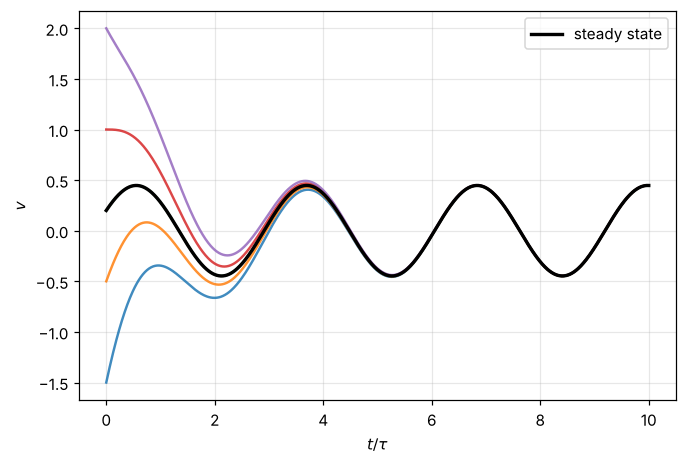

In [9]:
#| label: fig-driven-linear
#| caption: Solutions of v' + v/τ = A cos ωt from five initial velocities. The transient Ce^(−t/τ) dies out and every solution locks onto the same steady state (black).
tau, A, w = 1.0, 1.0, 2.0
t = np.linspace(0, 10, 800)
amp = A * tau / (1 + (w * tau)**2)
vp = amp * (np.cos(w * t) + w * tau * np.sin(w * t))

fig, ax = plt.subplots()
for v0 in [-1.5, -0.5, 0.2, 1.0, 2.0]:
    C = v0 - amp                        # from v(0) = v_p(0) + C
    ax.plot(t, vp + C * np.exp(-t / tau), lw=1.6, alpha=0.85)
ax.plot(t, vp, "k", lw=2.2, label="steady state")
ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel("$v$"); ax.legend(); plt.show()

In [10]:
# The integrating-factor recipe, step by step, for y' + 2 t y = t
t, C = sp.symbols("t C")
p, q = 2 * t, t
mu = sp.exp(sp.integrate(p, t))
y = (sp.integrate(mu * q, t) + C) / mu
print("mu(t) =", mu)
print("y(t)  =", sp.simplify(y))
y_fn = sp.Function("y")
print("check :", sp.simplify(y.diff(t) + p * y - q))

mu(t) = exp(t**2)
y(t)  = C*exp(-t**2) + 1/2
check : 0


:::{note} Used in the Newton's laws notes for
Linear drag in every direction: $\dot v_x = -v_x/\tau$ (homogeneous), $\dot v_y = g - v_y/\tau$ (constant forcing), and the approach to terminal velocity as a decaying transient.
:::

### Exercises

1. Solve $\dot v + v/\tau = a_0$ (constant $a_0$) with $v(0) = v_0$, and identify the transient and steady state.
2. Solve $\dot y + 2ty = t$.

:::{dropdown} Hints
1. The integrating factor is $e^{t/\tau}$.
2. The integrating factor is $e^{t^2}$, and $\int te^{t^2}dt = \tfrac12 e^{t^2}$.
:::

:::{dropdown} Answers
1. $v = a_0\tau + (v_0 - a_0\tau)e^{-t/\tau}$. The steady state is $a_0\tau$ (terminal velocity when $a_0 = g$), and the transient is the exponential.
2. $y = \tfrac12 + Ce^{-t^2}$.
:::

## Reducing the Order

Newton's second law is second order, but two common situations reduce it to first order.

### Force depends only on velocity

If $m\ddot x = F(\dot x)$, set $v = \dot x$. Then $m\dot v = F(v)$ is a first-order equation for $v$. Solve it, then integrate once more for $x$. Every drag problem works this way.

### Force depends only on position

If $m\ddot x = F(x)$, use the chain rule to trade time for position:

$$
\ddot x = \frac{dv}{dt} = \frac{dv}{dx}\frac{dx}{dt} = v\frac{dv}{dx} .
$$ (eq-v-dv-dx)

The equation $mv\,dv/dx = F(x)$ is separable:

$$
\tfrac12 mv^2 - \tfrac12 mv_0^2 = \int_{x_0}^{x}F(x')\,dx' .
$$

That is the work–energy theorem, derived here as an ODE trick. The energy method is really this reduction of order.

### Velocity as a function of distance

The same chain-rule trick also works for velocity-dependent forces when you care about distance rather than time. For coasting with quadratic drag, $mv\,dv/dx = -cv^2$ gives

$$
\frac{dv}{dx} = -\frac{c}{m}v \quad\Longrightarrow\quad v(x) = v_0e^{-cx/m} .
$$

The speed decays exponentially with distance, even though it decays only like $1/t$ in time.

### Exercises

1. For a mass on a spring ($F = -kx$), use {eq}`eq-v-dv-dx` to find $v$ as a function of $x$, starting from $v_0$ at $x = 0$.
2. A rock is dropped from height $h$ in vacuum. Use {eq}`eq-v-dv-dx` to find its speed when it lands, without finding $x(t)$.

:::{dropdown} Hints
1. Separate $v\,dv$ and $x\,dx$.
2. Take $x$ as height, with $F = -mg$.
:::

:::{dropdown} Answers
1. $v^2 = v_0^2 - (k/m)x^2$, which is energy conservation $\tfrac12mv^2 + \tfrac12kx^2 = \tfrac12mv_0^2$.
2. $\tfrac12v^2 = gh$, so $v = \sqrt{2gh}$.
:::

## Equilibria and Stability

For an autonomous first-order equation $\dot y = f(y)$, the long-time behavior can be read off from the graph of $f$ without solving anything.

- **Fixed points** (equilibria) are the roots $y^*$ of $f(y^*) = 0$.
- Where $f > 0$, $y$ increases. Where $f < 0$, it decreases.
- A fixed point is **stable** if nearby solutions move toward it. To linear order, setting $y = y^* + \epsilon$ gives

$$
\dot\epsilon \approx f'(y^*)\,\epsilon \quad\Longrightarrow\quad \epsilon(t) \approx \epsilon_0\,e^{f'(y^*)t} ,
$$ (eq-linearize)

  so $y^*$ is stable when $f'(y^*) < 0$ and unstable when $f'(y^*) > 0$.

This **linearization** is the single most useful idea in the qualitative theory of ODEs. In two or more dimensions it becomes the analysis of small oscillations and phase portraits at Levels 2 and 3.

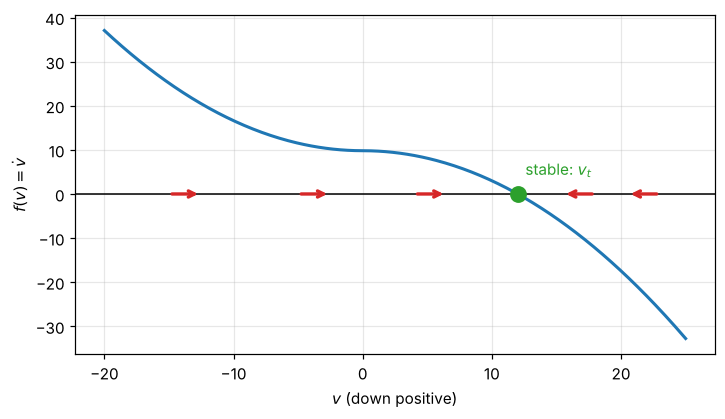

In [11]:
#| label: fig-phase-line
#| caption: Phase line for a falling object with quadratic drag, f(v) = g − k v|v|. The arrows show which way v moves. Terminal velocity is the only fixed point, and f′(v_t) < 0 makes it stable.
gval, vt = 9.81, 12.0
k = gval / vt**2
v = np.linspace(-20, 25, 400)
fv = gval - k * v * np.abs(v)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(v, fv, lw=2)
ax.axhline(0, color="k", lw=1)
for v0 in [-15, -5, 4, 18, 23]:
    d = np.sign(gval - k * v0 * abs(v0))
    ax.annotate("", xy=(v0 + 2.5 * d, 0), xytext=(v0, 0),
                arrowprops=dict(arrowstyle="->", color="tab:red", lw=2.2))
ax.plot(vt, 0, "o", ms=10, color="tab:green")
ax.annotate("stable: $v_t$", (vt, 0), textcoords="offset points", xytext=(5, 12), color="tab:green")
ax.set_xlabel("$v$ (down positive)"); ax.set_ylabel(r"$f(v) = \dot v$")
plt.show()

:::{note} Used in the Newton's laws notes for
Terminal velocity as an attracting fixed point, and the bead-on-hoop bifurcation, where a fixed point changes from stable to unstable as a parameter crosses a critical value.
:::

### Exercises

1. For falling with quadratic drag, compute $f'(v_t)$ and find the time constant for small deviations from terminal velocity.
2. Find and classify the fixed points of $\dot y = y(1 - y)(y - 2)$.

:::{dropdown} Hints
1. Near $v_t$, $f(v) = g - kv^2$ with $k = g/v_t^2$.
2. Expand $f$ as a cubic, or just evaluate $f'$ at each root.
:::

:::{dropdown} Answers
1. $f'(v_t) = -2kv_t = -2g/v_t$. Small deviations decay with time constant $v_t/(2g)$.
2. $y = 0$: $f'(0) = -2$, stable. $y = 1$: $f'(1) = 1$, unstable. $y = 2$: $f'(2) = -2$, stable.
:::

## Complex Numbers and Exponentials

A complex number $z = x + iy$ can be written in **polar form** using Euler's formula:

$$
e^{i\theta} = \cos\theta + i\sin\theta \qquad\Longrightarrow\qquad z = |z|\,e^{i\arg z} .
$$ (eq-euler)

Multiplying complex numbers multiplies their magnitudes and adds their angles. In particular, multiplying by $e^{i\theta}$ rotates by $\theta$, and multiplying by $-i = e^{-i\pi/2}$ rotates by $-90^\circ$.

### Why physicists use them for ODEs

The exponential is an eigenfunction of differentiation: $\frac{d}{dt}e^{st} = se^{st}$. For a linear equation with constant coefficients, the guess $e^{st}$ turns derivatives into multiplication by $s$, and the ODE becomes algebra. Complex $s$ covers oscillations and decaying oscillations in one formula:

$$
e^{(-\gamma + i\omega)t} = e^{-\gamma t}\big(\cos\omega t + i\sin\omega t\big) .
$$

### Packing two real equations into one complex equation

Rotations in a plane are multiplication by $e^{i\theta}$, so coupled equations that rotate a 2D vector collapse into one complex equation. Suppose a velocity in the plane rotates clockwise at rate $\omega$ while drag shrinks it at rate $\gamma$ (a charge in a magnetic field with linear drag):

$$
\dot v_x = -\gamma v_x + \omega v_y, \qquad \dot v_y = -\gamma v_y - \omega v_x .
$$

With $\eta = v_x + iv_y$ these become one equation:

$$
\dot\eta = -(\gamma + i\omega)\,\eta \quad\Longrightarrow\quad \eta(t) = \eta_0\,e^{-\gamma t}e^{-i\omega t} .
$$

The velocity spirals into the origin: its magnitude decays as $e^{-\gamma t}$ while its direction turns at rate $\omega$.

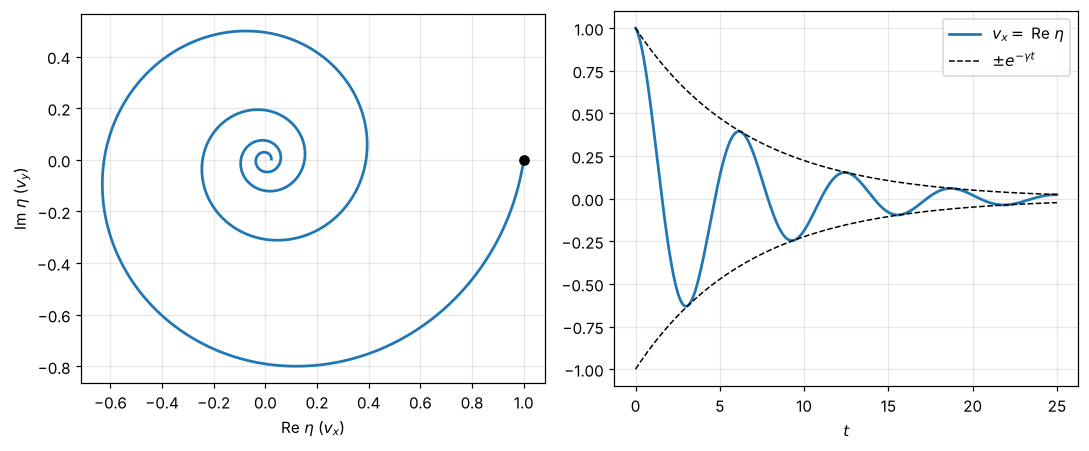

In [12]:
#| label: fig-complex-spiral
#| caption: Left, the complex velocity η(t) = η₀e^(−(γ+iω)t) spirals into the origin of the complex plane. Right, its real part is a decaying oscillation inside the envelope ±e^(−γt).
gam, w = 0.15, 1.0
t = np.linspace(0, 25, 1500)
eta = np.exp(-(gam + 1j * w) * t)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].plot(eta.real, eta.imag, lw=1.8)
axes[0].plot(1, 0, "ko")
axes[0].set_aspect("equal"); axes[0].set_xlabel(r"Re $\eta$ ($v_x$)"); axes[0].set_ylabel(r"Im $\eta$ ($v_y$)")
axes[1].plot(t, eta.real, lw=1.8, label=r"$v_x = $ Re $\eta$")
axes[1].plot(t, np.exp(-gam * t), "k--", lw=1, label=r"$\pm e^{-\gamma t}$")
axes[1].plot(t, -np.exp(-gam * t), "k--", lw=1)
axes[1].set_xlabel("$t$"); axes[1].legend()
plt.tight_layout(); plt.show()

:::{note} Used in the Newton's laws notes for
The charged particle in a magnetic field, and the steady-state solution of the periodically pushed puck. The next math step (linear second-order ODEs, before Taylor's oscillations chapter) is built entirely on this idea.
:::

### Exercises

1. Write $1 + i$ in polar form.
2. Show that $\operatorname{Re}\big[(a + ib)\,e^{i\omega t}\big] = a\cos\omega t - b\sin\omega t$ for real $a$, $b$.

:::{dropdown} Hints
1. Find the magnitude and the angle separately.
2. Expand $e^{i\omega t}$ with {eq}`eq-euler` and multiply out.
:::

:::{dropdown} Answers
1. $\sqrt2\,e^{i\pi/4}$.
2. $(a + ib)(\cos\omega t + i\sin\omega t)$ has real part $a\cos\omega t - b\sin\omega t$. Any sinusoid can be stored as one complex amplitude.
:::

## Series and Limiting Cases

An exact solution should reduce to a known result when a parameter becomes small: drag $\to 0$, angle $\to 0$, speed $\ll c$. Checking that requires Taylor series.

$$
f(x) = \sum_{n=0}^\infty \frac{f^{(n)}(0)}{n!}x^n = f(0) + f'(0)\,x + \tfrac12 f''(0)\,x^2 + \cdots
$$

The expansions used constantly in mechanics:

| Function | Series | Converges for |
|---|---|---|
| $e^x$ | $1 + x + \frac{x^2}{2} + \frac{x^3}{6} + \cdots$ | all $x$ |
| $\sin x$ | $x - \frac{x^3}{6} + \cdots$ | all $x$ |
| $\cos x$ | $1 - \frac{x^2}{2} + \frac{x^4}{24} - \cdots$ | all $x$ |
| $\ln(1+x)$ | $x - \frac{x^2}{2} + \frac{x^3}{3} - \cdots$ | $-1 < x \le 1$ |
| $(1+x)^n$ | $1 + nx + \frac{n(n-1)}{2}x^2 + \cdots$ | $\lvert x\rvert < 1$ (any real $n$) |
| $\tanh x$ | $x - \frac{x^3}{3} + \cdots$ | $\lvert x\rvert < \pi/2$ |

::::{prf:example} Recovering free fall from the drag solution
:label: ex-series-limit

For a short time after release, $t\ll\tau$, expand the linear-drag result $v = g\tau\left(1 - e^{-t/\tau}\right)$.

:::{dropdown} Solution
With $x = t/\tau$ small, $1 - e^{-x} = x - \tfrac12x^2 + \cdots$, so

$$
v = g\tau\left(\frac t\tau - \frac{t^2}{2\tau^2} + \cdots\right) = gt - \frac{gt^2}{2\tau} + \cdots
$$

The leading term is free fall. The first correction is negative (drag slows the object) and proportional to $1/\tau$, so it vanishes as drag disappears.
:::
::::

In [13]:
# Series in sympy. Note: .removeO() (capital letter O) strips the order term.
t, tau, g, x = sp.symbols("t tau g x", positive=True)
v = g * tau * (1 - sp.exp(-t / tau))
print("v for t << tau  :", sp.series(v, t, 0, 3).removeO())

vt = sp.symbols("v_t", positive=True)
v_quad = vt * sp.tanh(g * t / vt)
print("tanh solution   :", sp.series(v_quad, t, 0, 4).removeO())
print("1/sqrt(1 - x^2) :", sp.series(1 / sp.sqrt(1 - x**2), x, 0, 6).removeO())

v for t << tau  : -g*t**2/(2*tau) + g*t
tanh solution   : -g**3*t**3/(3*v_t**2) + g*t
1/sqrt(1 - x^2) : 3*x**4/8 + x**2/2 + 1


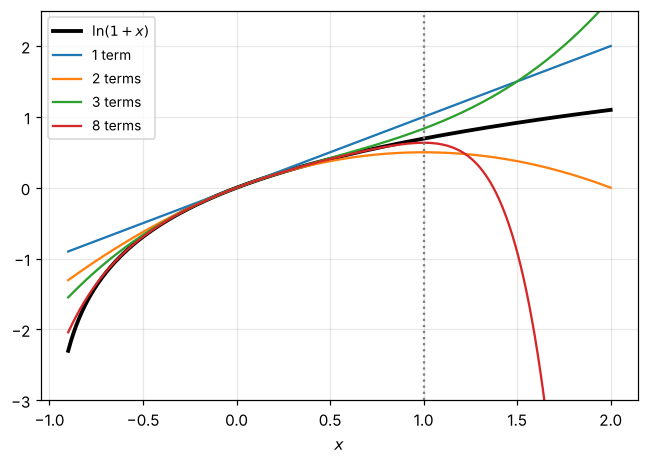

In [14]:
#| label: fig-series
#| caption: Partial sums of the series for ln(1 + x). They converge quickly for small x but fail for x > 1, outside the radius of convergence. Expansions are only trustworthy when the small parameter really is small.
x = np.linspace(-0.9, 2.0, 400)
fig, ax = plt.subplots()
ax.plot(x, np.log1p(x), "k", lw=2.5, label=r"$\ln(1+x)$")
for N, c in [(1, "tab:blue"), (2, "tab:orange"), (3, "tab:green"), (8, "tab:red")]:
    s = sum((-1)**(n + 1) * x**n / n for n in range(1, N + 1))
    ax.plot(x, s, color=c, lw=1.5, label=f"{N} term{'s' if N > 1 else ''}")
ax.axvline(1, color="gray", ls=":")
ax.set_ylim(-3, 2.5); ax.set_xlabel("$x$"); ax.legend(fontsize=9)
plt.show()

### Exercises

1. Expand $\dfrac{1}{\sqrt{1 - x^2}}$ to order $x^4$.
2. The maximum height with linear drag is $y_{\max} = \tau\left[v_0 - v_t\ln(1 + v_0/v_t)\right]$. Expand for $v_0\ll v_t$ to first order beyond the vacuum result.

:::{dropdown} Hints
1. Use $(1+u)^{-1/2}$ with $u = -x^2$.
2. Keep three terms of $\ln(1+\epsilon)$ with $\epsilon = v_0/v_t$, and use $v_t = g\tau$.
:::

:::{dropdown} Answers
1. $1 + \tfrac12x^2 + \tfrac38x^4$.
2. $y_{\max}\approx\dfrac{v_0^2}{2g} - \dfrac{v_0^3}{3g\,v_t}$. The correction is negative and vanishes as $v_t\to\infty$.
:::

## Solving ODEs Numerically

Most equations of motion have no closed-form solution. The numerical approach always starts the same way: write the problem as a **first-order system**. For Newton's second law in one dimension, the state is $(x, v)$:

$$
\frac{d}{dt}\begin{pmatrix} x \\ v\end{pmatrix} = \begin{pmatrix} v \\ F(x, v, t)/m\end{pmatrix} .
$$

Any ODE solver takes a function that returns this right-hand side.

### Euler's method

The simplest method steps along the tangent line:

$$
y_{n+1} = y_n + h\,f(t_n, y_n) .
$$

It is easy to understand and a poor choice in practice. Its error per unit time is proportional to $h$ (first order), so ten times the accuracy costs ten times the steps.

### Runge–Kutta methods

**RK4** samples the slope four times per step and combines them:

$$
\begin{aligned}
k_1 &= f(t_n, y_n), & k_2 &= f\!\left(t_n + \tfrac h2,\ y_n + \tfrac h2k_1\right),\\
k_3 &= f\!\left(t_n + \tfrac h2,\ y_n + \tfrac h2k_2\right), & k_4 &= f(t_n + h,\ y_n + hk_3),
\end{aligned}
\qquad
y_{n+1} = y_n + \frac h6\left(k_1 + 2k_2 + 2k_3 + k_4\right) .
$$

Its error scales as $h^4$: halving the step cuts the error by a factor of 16. Library solvers such as `scipy.integrate.solve_ivp` use adaptive Runge–Kutta variants that also adjust $h$ automatically to meet a tolerance.

In [15]:
# Hand-written steppers, each working on a state vector y (a NumPy array)
def euler_step(f, t, y, h):
    return y + h * f(t, y)

def midpoint_step(f, t, y, h):                 # second-order Runge-Kutta
    k1 = f(t, y)
    return y + h * f(t + h / 2, y + h / 2 * k1)

def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def integrate(step, f, y0, t_end, h):
    n = int(round(t_end / h))
    t, y = 0.0, np.atleast_1d(np.asarray(y0, dtype=float))
    for _ in range(n):
        y = step(f, t, y, h)
        t += h
    return y

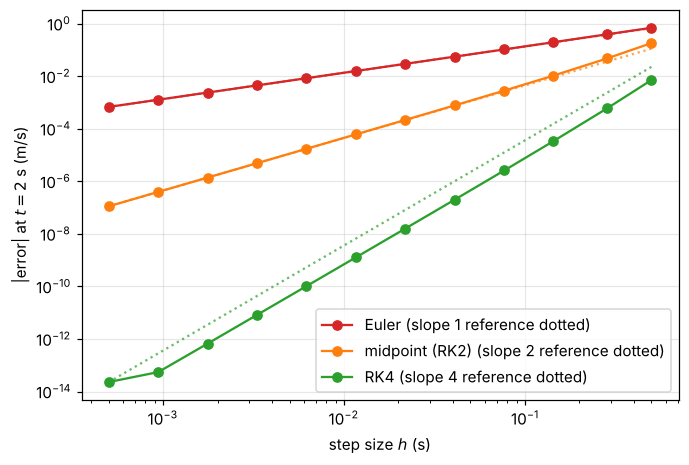

In [16]:
#| label: fig-convergence
#| caption: Error at t = 2 s for falling with quadratic drag, as the step size shrinks. On log axes the slopes are 1 (Euler), 2 (midpoint) and 4 (RK4), the orders of the methods.
gval, vt = 9.81, 12.0
k = gval / vt**2
f = lambda t, y: np.array([gval - k * y[0] * abs(y[0])])
exact = vt * np.tanh(gval * 2.0 / vt)

# Step sizes that divide the 2 s interval exactly (see the warning below)
Ns = np.unique(np.round(np.logspace(0.6, 3.6, 12)).astype(int))
hs = 2.0 / Ns
fig, ax = plt.subplots()
for name, step, c, p in [("Euler", euler_step, "tab:red", 1), ("midpoint (RK2)", midpoint_step, "tab:orange", 2),
                         ("RK4", rk4_step, "tab:green", 4)]:
    err = np.array([abs(integrate(step, f, [0.0], 2.0, h)[0] - exact) for h in hs])
    ax.loglog(hs, err, "o-", color=c, label=f"{name} (slope {p} reference dotted)")
    ax.loglog(hs, err[-1] * (hs / hs[-1])**p, ":", color=c, alpha=0.7)   # line of slope p through the largest-h point
ax.set_xlabel("step size $h$ (s)"); ax.set_ylabel("|error| at $t = 2$ s (m/s)")
ax.legend(); plt.show()

:::{warning} Make the steps land on the end time
The step sizes in this test are chosen as $h = 2\ \text{s}/N$ for whole numbers $N$. A first draft of this figure used arbitrary step sizes and rounded $2/h$ to a whole number of steps, so each run stopped up to $h/2$ short of or past $t = 2$ s. That endpoint mismatch adds an error proportional to $h$, and it made all three methods look first order. When a high-order method converges at the wrong rate, check the bookkeeping (end times, step counts) before blaming the method.
:::

### Stability: when a step is too big

Accuracy is one problem. Stability is another. Apply Euler's method to pure decay, $\dot v = -v/\tau$:

$$
v_{n+1} = v_n - \frac h\tau v_n = \left(1 - \frac h\tau\right)v_n .
$$

The numerical solution is multiplied by $(1 - h/\tau)$ each step. If $h > 2\tau$, that factor has magnitude greater than 1, and the "decaying" solution grows and flips sign every step. The physics says the velocity dies away; the method says it explodes. Equations with a fast time scale (**stiff** equations) need either tiny steps or implicit methods.

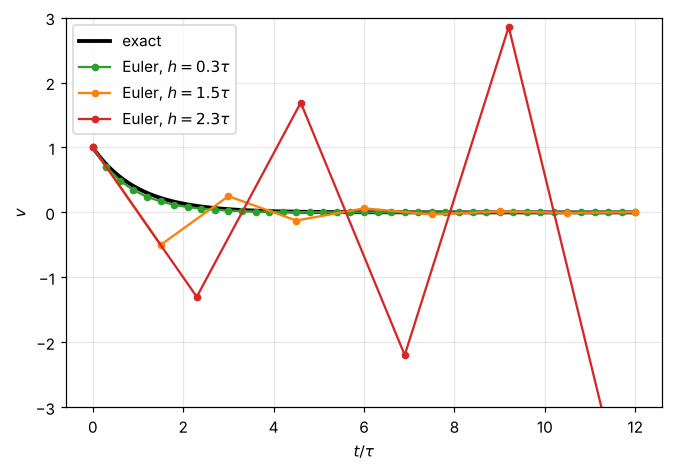

In [17]:
#| label: fig-euler-unstable
#| caption: Euler's method on v' = −v/τ. A small step tracks the exact decay, a step between τ and 2τ overshoots and oscillates, and a step above 2τ blows up.
tau = 1.0
fig, ax = plt.subplots()
tt = np.linspace(0, 12, 300)
ax.plot(tt, np.exp(-tt / tau), "k", lw=2.5, label="exact")
for h, c in [(0.3, "tab:green"), (1.5, "tab:orange"), (2.3, "tab:red")]:
    n = int(12 / h)
    ts = np.arange(n + 1) * h
    vs = (1 - h / tau) ** np.arange(n + 1)
    ax.plot(ts, vs, "o-", color=c, ms=4, label=rf"Euler, $h = {h}\tau$")
ax.set_ylim(-3, 3); ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel("$v$"); ax.legend()
plt.show()

:::{note} Used in the Newton's laws notes for
The large-amplitude pendulum, the baseball with quadratic drag, and the charge in crossed electric and magnetic fields were all solved with `solve_ivp`. Its default method (RK45) is an adaptive fourth/fifth-order Runge–Kutta scheme.
:::

### Exercises

1. Use the convergence figure to estimate how much smaller the RK4 error becomes when you halve $h$. How does that compare with Euler?
2. Write the pendulum equation $\ddot\phi = -(g/L)\sin\phi$ as a first-order system and give the right-hand-side function you would pass to `solve_ivp`.

:::{dropdown} Hints
1. The slopes on the log-log plot are the orders of the methods.
2. Use the state $(\phi, \omega)$ with $\omega = \dot\phi$.
:::

:::{dropdown} Answers
1. A factor of $2^4 = 16$ for RK4, compared with a factor of 2 for Euler, at the cost of four function evaluations per step instead of one.
2. `def rhs(t, s): phi, om = s; return [om, -(g / L) * np.sin(phi)]`
:::

## Summary

| Tool | Main idea | Where it shows up in Newton's laws |
|---|---|---|
| Dot and cross products | projection; perpendicular area vector | force components, torque, $q\mathbf{v}\times\mathbf{B}$ |
| Index notation | $\varepsilon_{ijk}$, $\delta_{ij}$, and {eq}`eq-eps-delta` | vector identities; Goldstein's notation |
| Vector derivatives | constant length ⇒ derivative perpendicular | polar unit vectors, rotating vectors |
| Curvilinear coordinates | moving unit vectors add terms | polar $\mathbf{F} = m\mathbf{a}$, pendulum |
| Separable ODEs | $\int dy/h(y) = \int g\,dt$; keep constant solutions | quadratic drag |
| Linear first-order ODEs | integrating factor; transient + steady state | linear drag, periodic forcing |
| Reduction of order | $\ddot x = v\,dv/dx$ | energy, velocity vs. distance |
| Stability | sign of $f'(y^*)$ | terminal velocity, bifurcations |
| Complex exponentials | derivatives become multiplication | magnetic force, forced response |
| Series | check limits, estimate corrections | small drag, small angles |
| Numerical methods | first-order system, RK4, step-size stability | baseball, pendulum, crossed fields |

**Next math step on the plan:** complex numbers and second-order linear ODEs with constant coefficients (damped and driven oscillators), plus Fourier series, before Taylor's oscillations chapter.

## Appendix: MyST patterns used here

Same conventions as the other two notebooks. One addition: a **proof that starts collapsed**, useful for short arguments you want available but not in the way:

````md
:::{prf:theorem} Constant length means perpendicular derivative
:label: thm-const-length
If $|\mathbf{A}(t)|$ is constant, then $\dot{\mathbf{A}}\perp\mathbf{A}$.
:::

:::{prf:proof}
:class: dropdown
$\mathbf{A}\cdot\mathbf{A}$ is constant, so its derivative $2\mathbf{A}\cdot\dot{\mathbf{A}}$ is zero.
:::
````